<a href="https://colab.research.google.com/github/ASHIK-77/ML-LAB/blob/main/EXP10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [3]:
# Select features and target
features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[features].copy()
y = df["Survived"]

# Fill missing numerical values with the median
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

# Fill missing categorical values with the most frequent value
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, columns=["Sex", "Embarked"], drop_first=True)

print("Preprocessed features:")
print(X.head())

print("\nMissing values after preprocessing:")
print(X.isnull().sum().sum())

Preprocessed features:
   Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2500      True       False        True
1       1  38.0      1      0  71.2833     False       False       False
2       3  26.0      0      0   7.9250     False       False        True
3       1  35.0      1      0  53.1000     False       False        True
4       3  35.0      0      0   8.0500      True       False        True

Missing values after preprocessing:
0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [5]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

# Train the model
bagging_model.fit(X_train, y_train)

# Predict on test data
bagging_predictions = bagging_model.predict(X_test)

print("Bagging Classification Report:")
print(classification_report(
    y_test,
    bagging_predictions,
    zero_division=0
))

Bagging Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.80      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.83       179



In [6]:
bagging_accuracy = accuracy_score(y_test, bagging_predictions)

bagging_precision = precision_score(
    y_test, bagging_predictions, zero_division=0
)

bagging_recall = recall_score(
    y_test, bagging_predictions, zero_division=0
)

bagging_f1 = f1_score(
    y_test, bagging_predictions, zero_division=0
)

print("Bagging Performance")
print("-------------------")
print("Accuracy :", round(bagging_accuracy, 4))
print("Precision:", round(bagging_precision, 4))
print("Recall   :", round(bagging_recall, 4))
print("F1-score :", round(bagging_f1, 4))

Bagging Performance
-------------------
Accuracy : 0.8268
Precision: 0.7969
Recall   : 0.7391
F1-score : 0.7669


In [7]:
boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train the model
boosting_model.fit(X_train, y_train)

# Predict on test data
boosting_predictions = boosting_model.predict(X_test)

print("Boosting Classification Report:")
print(classification_report(
    y_test,
    boosting_predictions,
    zero_division=0
))

Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       110
           1       0.72      0.72      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



In [8]:
boosting_accuracy = accuracy_score(y_test, boosting_predictions)

boosting_precision = precision_score(
    y_test, boosting_predictions, zero_division=0
)

boosting_recall = recall_score(
    y_test, boosting_predictions, zero_division=0
)

boosting_f1 = f1_score(
    y_test, boosting_predictions, zero_division=0
)

print("Boosting Performance")
print("--------------------")
print("Accuracy :", round(boosting_accuracy, 4))
print("Precision:", round(boosting_precision, 4))
print("Recall   :", round(boosting_recall, 4))
print("F1-score :", round(boosting_f1, 4))

Boosting Performance
--------------------
Accuracy : 0.7877
Precision: 0.7246
Recall   : 0.7246
F1-score : 0.7246


In [9]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Bagging": [
        bagging_accuracy,
        bagging_precision,
        bagging_recall,
        bagging_f1
    ],
    "Boosting": [
        boosting_accuracy,
        boosting_precision,
        boosting_recall,
        boosting_f1
    ]
})

print(comparison.round(4).to_string(index=False))

   Metric  Bagging  Boosting
 Accuracy   0.8268    0.7877
Precision   0.7969    0.7246
   Recall   0.7391    0.7246
 F1-score   0.7669    0.7246


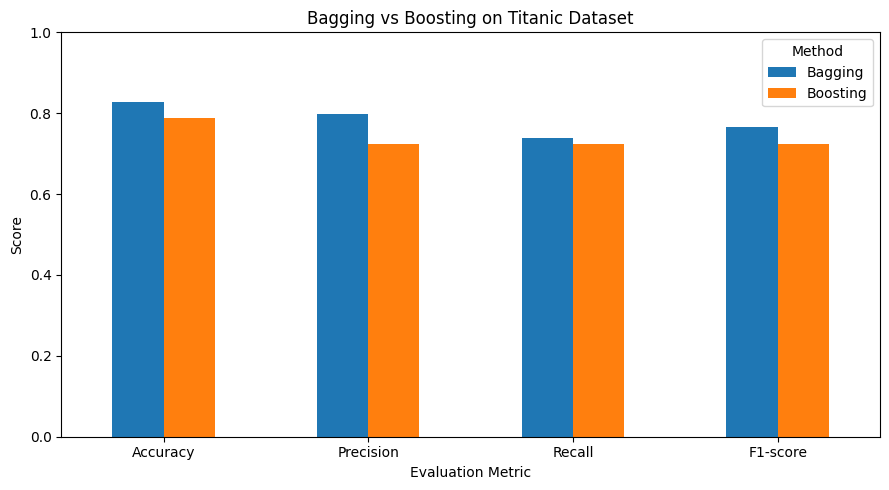

In [10]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Bagging vs Boosting on Titanic Dataset")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Method")
plt.tight_layout()
plt.show()

In [11]:
for metric in ["Accuracy", "Precision", "Recall", "F1-score"]:
    bagging_score = comparison.loc[
        comparison["Metric"] == metric, "Bagging"
    ].iloc[0]

    boosting_score = comparison.loc[
        comparison["Metric"] == metric, "Boosting"
    ].iloc[0]

    if bagging_score > boosting_score:
        print(metric + ": Bagging performs better")
    elif boosting_score > bagging_score:
        print(metric + ": Boosting performs better")
    else:
        print(metric + ": Both methods have equal scores")

Accuracy: Bagging performs better
Precision: Bagging performs better
Recall: Bagging performs better
F1-score: Bagging performs better
